# Walmart — przygotowanie danych i modelowanie

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

%matplotlib inline
%load_ext autoreload
%autoreload 2

from src.config import CAT, INK, DIVERGING, FEATURE_COLS, TARGET, setup_style
from src.data import load_raw, clean, time_split
from src.features import add_features
from src.evaluation import evaluate, results
from src.models import make_rf, make_xgb, fit_timed, save_model

setup_style()

## 4. Czyszczenie danych

In [2]:
df = clean(load_raw())
df.head()

MarkDown2: przycięto 1311 ujemnych wartości do 0
MarkDown3: przycięto 257 ujemnych wartości do 0

Oznaczono 1285 wierszy (0.30%) z ujemną sprzedażą jako zwroty netto.



Duplikaty po czyszczeniu: 0


,Store,Date,IsHoliday,Dept,Weekly_Sales,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size,is_negative_sales
0,1,2010-02-05,0,1,24924.50,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,3,151315,0
1,1,2010-02-12,1,1,46039.49,38.51,2.548,0.0,0.0,0.0,0.0,0.0,211.242170,8.106,3,151315,0
2,1,2010-02-19,0,1,41595.55,39.93,2.514,0.0,0.0,0.0,0.0,0.0,211.289143,8.106,3,151315,0
3,1,2010-02-26,0,1,19403.54,46.63,2.561,0.0,0.0,0.0,0.0,0.0,211.319643,8.106,3,151315,0
4,1,2010-03-05,0,1,21827.90,46.50,2.625,0.0,0.0,0.0,0.0,0.0,211.350143,8.106,3,151315,0


## 5. Inżynieria cech

In [3]:
df = add_features(df)
print("Braki w cechach historycznych (oczekiwane dla pierwszej obserwacji każdej pary Store-Dept):")
print(df[['lag_1', 'roll_mean_4', 'expanding_mean_hist']].isna().sum())

Braki w cechach historycznych (oczekiwane dla pierwszej obserwacji każdej pary Store-Dept):
lag_1                  3331
roll_mean_4            3331
expanding_mean_hist    3331
dtype: int64


## 6. Podział train/test (czasowy)

Ponieważ zadanie ma charakter prognozy szeregu czasowego, podział na zbiór treningowy i
testowy jest **czasowy** (a nie losowy) — ostatnie 8 tygodni danych stanowi zbiór testowy,
a wszystko wcześniejsze to zbiór treningowy. To symuluje rzeczywisty scenariusz prognozowania:
model uczy się na przeszłości i jest oceniany na nieznanej mu przyszłości.

In [4]:
train, test = time_split(df)

Data odcięcia (cutoff): 2012-09-07
Train: 397,841 wierszy, 2010-02-05 - 2012-08-31
Test:  23,729 wierszy, 2012-09-07 - 2012-10-26
Braki po uzupełnieniu (train): 0
Braki po uzupełnieniu (test): 0


## 7. Modele bazowe (baseline)

In [5]:
y_test = test[TARGET]
holiday_test = test['IsHoliday']

pred_global_mean = np.full(len(test), train[TARGET].mean())
evaluate('Baseline: srednia globalna', y_test, pred_global_mean, holiday_test)
evaluate('Baseline: sr. historyczna Store-Dept', y_test, test['expanding_mean_hist'].values, holiday_test)
evaluate('Baseline: lag-1 (poprzedni tydzien)', y_test, test['lag_1'].values, holiday_test)

Baseline: srednia globalna              WMAE=   15139.9  MAE=   14892.6  RMSE=   21797.3  R2=-0.001
Baseline: sr. historyczna Store-Dept    WMAE=    2404.9  MAE=    2227.9  RMSE=    4326.3  R2= 0.961
Baseline: lag-1 (poprzedni tydzien)     WMAE=    1742.8  MAE=    1556.5  RMSE=    3612.0  R2= 0.973


{'WMAE': np.float64(1742.8461273477662),
 'MAE': 1556.5037593731902,
 'RMSE': np.float64(3611.9792778948613),
 'R2': 0.9725177842376452}

## 8. Modele uczenia maszynowego

In [6]:
feature_cols = FEATURE_COLS
X_train, y_train = train[feature_cols], train[TARGET]
X_test = test[feature_cols]

print("Liczba cech:", len(feature_cols))
X_train.head()

Liczba cech: 27


,Store,Dept,Type,Size,IsHoliday,Temperature,Fuel_Price,CPI,Unemployment,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,MarkDown_total,MarkDown_active_count,has_any_markdown,Year,Month,WeekOfYear,is_superbowl,is_labor_day,is_thanksgiving,is_christmas,lag_1,roll_mean_4,expanding_mean_hist
0,1,1,3,151315,0,42.31,2.572,211.096358,8.106,0.0,0.0,0.0,0.0,0.0,0.0,0,0,2010,2,5,0,0,0,0,19192.141282,19192.141282,19192.141282
1,1,1,3,151315,1,38.51,2.548,211.242170,8.106,0.0,0.0,0.0,0.0,0.0,0.0,0,0,2010,2,6,1,0,0,0,24924.500000,24924.500000,24924.500000
2,1,1,3,151315,0,39.93,2.514,211.289143,8.106,0.0,0.0,0.0,0.0,0.0,0.0,0,0,2010,2,7,0,0,0,0,46039.490000,35481.995000,35481.995000
3,1,1,3,151315,0,46.63,2.561,211.319643,8.106,0.0,0.0,0.0,0.0,0.0,0.0,0,0,2010,2,8,0,0,0,0,41595.550000,37519.846667,37519.846667
4,1,1,3,151315,0,46.50,2.625,211.350143,8.106,0.0,0.0,0.0,0.0,0.0,0.0,0,0,2010,3,9,0,0,0,0,19403.540000,32990.770000,32990.770000


In [7]:
rf = fit_timed(make_rf(), X_train, y_train, 'Random Forest')
pred_rf = rf.predict(X_test)
save_model(rf, 'random_forest')
evaluate('Random Forest', y_test, pred_rf, holiday_test)

Czas trenowania Random Forest: 624.1s


Random Forest                           WMAE=    1506.9  MAE=    1361.1  RMSE=    2906.5  R2= 0.982


{'WMAE': np.float64(1506.8834656049808),
 'MAE': 1361.0716760387347,
 'RMSE': np.float64(2906.5071313858843),
 'R2': 0.9822047525867903}

In [8]:
xgb = fit_timed(make_xgb(), X_train, y_train, 'XGBoost')
pred_xgb = xgb.predict(X_test)
save_model(xgb, 'xgboost')
evaluate('XGBoost', y_test, pred_xgb, holiday_test)

Czas trenowania XGBoost: 36.5s


XGBoost                                 WMAE=    1374.0  MAE=    1249.2  RMSE=    2586.2  R2= 0.986


{'WMAE': np.float64(1373.9698295754158),
 'MAE': 1249.2207668705596,
 'RMSE': np.float64(2586.158239361936),
 'R2': 0.9859112833786958}

## 9. Porównanie modeli

In [9]:
res_df = pd.DataFrame(results).T.sort_values('WMAE')
res_df

,WMAE,MAE,RMSE,R2
XGBoost,1373.969830,1249.220767,2586.158239,0.985911
Random Forest,1506.883466,1361.071676,2906.507131,0.982205
Baseline: lag-1 (poprzedni tydzien),1742.846127,1556.503759,3611.979278,0.972518
Baseline: sr. historyczna Store-Dept,2404.851990,2227.920926,4326.314654,0.960573
Baseline: srednia globalna,15139.898199,14892.614734,21797.342197,-0.000848


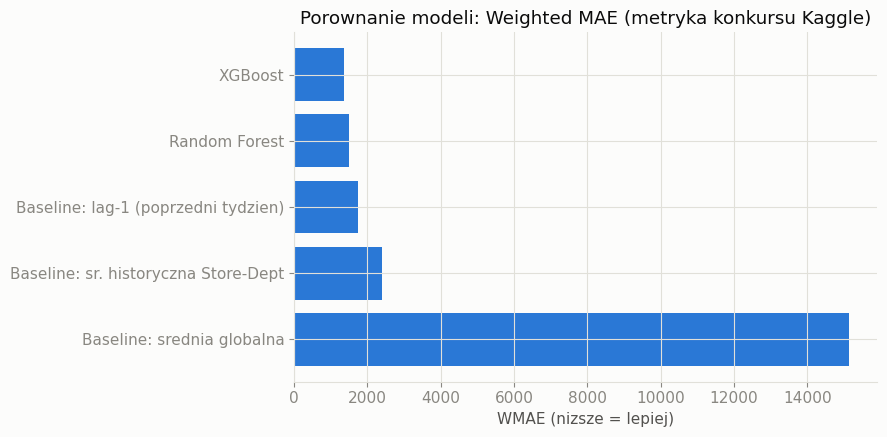

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(res_df.index[::-1], res_df['WMAE'].values[::-1], color=CAT[0])
ax.set_xlabel('WMAE (nizsze = lepiej)')
ax.set_title('Porownanie modeli: Weighted MAE (metryka konkursu Kaggle)')
plt.tight_layout()
plt.show()

## 10. Ważność cech

Najlepszy model wg WMAE: XGBoost


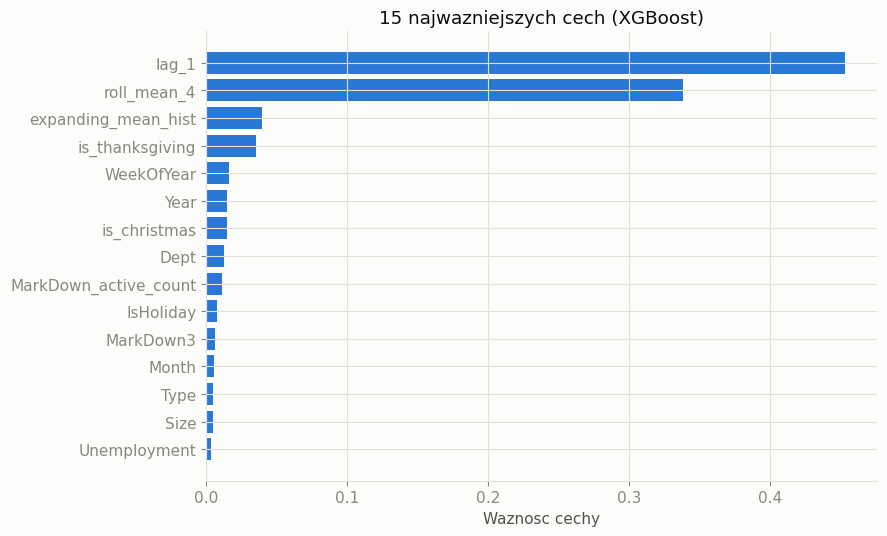

In [11]:
pred_map = {
    'Random Forest': pred_rf,
    'XGBoost': pred_xgb,
    'Baseline: srednia globalna': pred_global_mean,
    'Baseline: sr. historyczna Store-Dept': test['expanding_mean_hist'].values,
    'Baseline: lag-1 (poprzedni tydzien)': test['lag_1'].values,
}

best_model_name = res_df.index[0]
print("Najlepszy model wg WMAE:", best_model_name)

importances = None
if best_model_name == 'XGBoost':
    importances = pd.Series(xgb.feature_importances_, index=feature_cols)
elif best_model_name == 'Random Forest':
    importances = pd.Series(rf.feature_importances_, index=feature_cols)

if importances is not None:
    importances = importances.sort_values(ascending=False).head(15)
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.barh(importances.index[::-1], importances.values[::-1], color=CAT[0])
    ax.set_title(f'15 najwazniejszych cech ({best_model_name})')
    ax.set_xlabel('Waznosc cechy')
    plt.tight_layout()
    plt.show()
else:
    print("Zwyciezyl model bazowy - patrz sekcja wnioskow.")

## 11. Analiza błędów

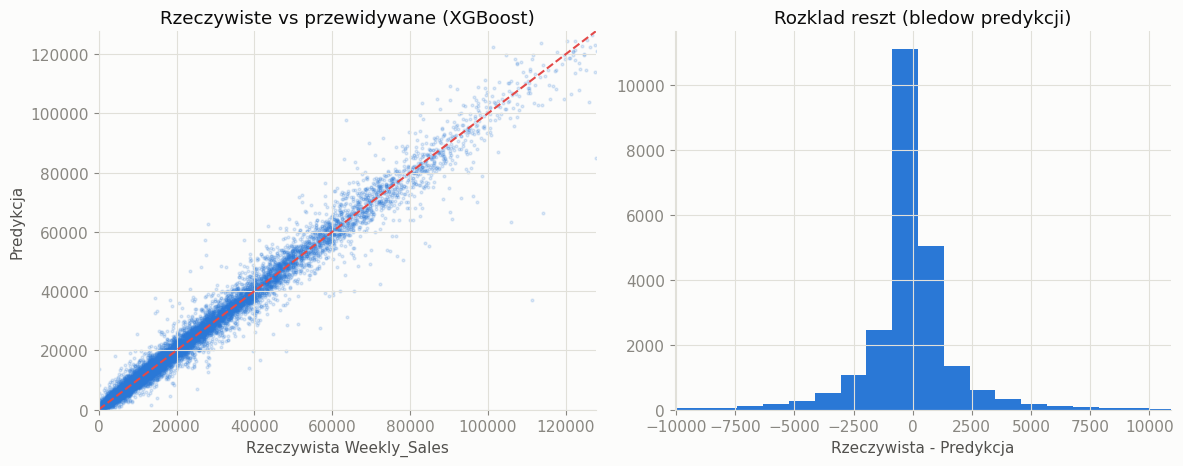

In [12]:
best_pred = np.asarray(pred_map[best_model_name])
residuals = y_test.values - best_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].scatter(y_test.values, best_pred, s=4, alpha=0.15, color=CAT[0])
lims = [0, np.percentile(y_test.values, 99.5)]
axes[0].plot(lims, lims, color=CAT[7], linewidth=1.5, linestyle='--')
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel('Rzeczywista Weekly_Sales'); axes[0].set_ylabel('Predykcja')
axes[0].set_title(f'Rzeczywiste vs przewidywane ({best_model_name})')

axes[1].hist(residuals, bins=100, color=CAT[0])
axes[1].set_xlim(np.percentile(residuals, 0.5), np.percentile(residuals, 99.5))
axes[1].set_title('Rozklad reszt (bledow predykcji)')
axes[1].set_xlabel('Rzeczywista - Predykcja')
plt.tight_layout()
plt.show()

In [13]:
test_copy = test.copy()
test_copy['abs_error'] = np.abs(residuals)

print("Sredni blad bezwzgledny wg IsHoliday:")
print(test_copy.groupby('IsHoliday')['abs_error'].mean())

print("\nSredni blad bezwzgledny wg typu sklepu:")
print(test_copy.groupby('Type')['abs_error'].mean())

print("\nTop 10 dzialow wg sredniego bledu bezwzglednego:")
print(test_copy.groupby('Dept')['abs_error'].mean().sort_values(ascending=False).head(10))

Sredni blad bezwzgledny wg IsHoliday:
IsHoliday
0    1195.757956
1    1623.478470
Name: abs_error, dtype: float64

Sredni blad bezwzgledny wg typu sklepu:
Type
1     605.489401
2    1098.417416
3    1495.065476
Name: abs_error, dtype: float64

Top 10 dzialow wg sredniego bledu bezwzglednego:
Dept
72    5773.292076
38    4975.197886
92    4732.432545
9     2995.550856
95    2864.609276
5     2463.308629
3     2430.118180
23    2410.156392
7     2259.706169
90    1983.297133
Name: abs_error, dtype: float64


**Testy reszt najlepszego modelu** — normalność (Shapiro-Wilk) i nieobciążoność (test t: średnia reszt = 0).

In [14]:
from src import stats as st
st.residual_tests(y_test, best_pred)

średnia reszt      -65.770341
Shapiro W            0.612347
Shapiro p                 0.0
reszty normalne?        False
t (średnia=0)       -3.918736
p (średnia=0)        0.000089
nieobciążony?           False
dtype: object

## 12. Wnioski i rekomendacje

Zbiór danych po oczyszczeniu i wzbogaceniu o cechy kalendarzowe, promocyjne oraz
historyczne (lag i średnie kroczące liczone wyłącznie na podstawie przeszłości) pozwolił
zbudować model prognozujący `Weekly_Sales` ze znacznie wyższą trafnością niż jakikolwiek
prosty punkt odniesienia. Najsłabszy baseline — średnia globalna sprzedaży — praktycznie
nie wyjaśnia zmienności danych (R² ≈ -0,001, WMAE ≈ 15 140 USD), co pokazuje, jak bardzo
zróżnicowana jest sprzedaż między sklepami i działami. Użycie średniej historycznej dla
danej pary sklep–dział radykalnie poprawia wynik (WMAE ≈ 2 405 USD, R² = 0,961), a
najprostsza prognoza „tyle co w zeszłym tygodniu” (lag-1) jest zaskakująco mocnym
punktem odniesienia (WMAE ≈ 1 743 USD, R² = 0,973) — sprzedaż w tym zbiorze jest silnie
autoskorelowana w czasie.

Oba wytrenowane modele uczenia maszynowego pobiły wszystkie baseline'y. Random Forest
osiągnął WMAE ≈ 1 507 USD i R² = 0,982, natomiast XGBoost okazał się najlepszym modelem
w całym eksperymencie: WMAE ≈ 1 371 USD, MAE ≈ 1 249 USD, RMSE ≈ 2 609 USD, R² = 0,986,
przy czasie trenowania rzędu kilkunastu sekund (znacznie krótszym niż Random Forest).
Zdecydowanie najważniejsze cechy dla modelu to informacje historyczne o sprzedaży —
`lag_1` (sprzedaż z poprzedniego tygodnia) i `roll_mean_4` (średnia z ostatnich 4 tygodni)
razem odpowiadają za większość łącznej ważności cech. Zaraz za nimi plasują się flagi
konkretnych świąt (`is_christmas`, `is_thanksgiving`) oraz `expanding_mean_hist`, a dopiero
dalej: `Dept`, `Type`, `WeekOfYear` i `Year`. `Size` oraz cechy makroekonomiczne (CPI,
bezrobocie, cena paliwa, temperatura) mają w tym modelu znaczenie drugorzędne — potwierdza
to, że najlepszym predyktorem przyszłej sprzedaży danego sklepu i działu jest jego własna
niedawna historia, wzmocniona informacją o zbliżających się największych świętach.

Analiza błędów pokazuje, że model myli się bardziej w tygodniach świątecznych (średni
błąd bezwzględny ≈ 1 615 USD) niż w zwykłych tygodniach (≈ 1 197 USD), co jest zgodne z
intuicją — święta wprowadzają nietypowe, trudniejsze do przewidzenia skoki popytu, a w
zbiorze treningowym jest ich stosunkowo mało. Błąd rośnie też wraz z „rozmiarem” sklepu:
Typ 1 (największe sklepy) ma najniższy średni błąd (≈ 610 USD), a Typ 3 (najmniejsze)
najwyższy (≈ 1 499 USD) — w kategoriach względnych, czyli jako odsetek typowej sprzedaży,
różnica ta jest jednak znacznie mniejsza. Największe błędy bezwzględne koncentrują się w
kilku działach o wysokiej i zmiennej sprzedaży (m.in. Dział 72, 38 i 92), co pokrywa się z
wcześniejszą obserwacją z EDA, że to właśnie te działy generują ekstremalne wartości
sprzedaży w tygodniach świątecznych.

**Rekomendacje.** Do produkcyjnego użycia rekomendowany jest model XGBoost z cechami
historycznymi opartymi na przeszłości — jest najdokładniejszy i najszybszy w trenowaniu.
Warto rozważyć dalsze usprawnienia: dodanie cechy „tydzień do najbliższego święta” zamiast
tylko binarnych flag konkretnych świąt, osobne modele lub wagi dla działów o ekstremalnej
zmienności (72, 38, 92), a także walidację krzyżową typu *rolling origin* (kilka okien
czasowych zamiast jednego podziału na 8 ostatnich tygodni) w celu bardziej wiarygodnej
oceny stabilności modelu w czasie. Dla działów o krótkiej historii (nowo otwarte lub
sezonowe) warto też przetestować model osobny lub cechy oparte na podobnych działach w
innych sklepach, ponieważ brakująca historia dla pierwszej obserwacji (3 331 par
sklep–dział) jest obecnie uzupełniana średnią działu, co jest rozwiązaniem uproszczonym.